# 10 · Interference holograms and field reconstruction

A simple computer-generated hologram can be made by interfering a reference field with a target field, then encoding the resulting modulation in a binary mask. Propagation reveals the reconstructed component.

This is the package-user version: imports come first, and each operation is introduced when the physical question calls for it.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from topolino import propTF2


## 1. Create reference and target waves

We use a tilted plane wave as the reference and a displaced Gaussian as a simple target. Their complex sum contains the interference fringes.

In [ ]:
lambda_m = 500e-9
window_m = 2e-3
n = 512
x_m = np.linspace(-window_m/2, window_m/2, n, endpoint=False)
X, Y = np.meshgrid(x_m, x_m)
reference = np.ones((n,n), dtype=complex)
target = np.exp(-((X-150e-6)**2+Y**2)/(2*(60e-6)**2))


## 2. Threshold the fringes into an amplitude hologram

A binary mask is a simplified encoding. It discards continuous amplitude information, so reconstruction is approximate and depends on the chosen threshold.

In [ ]:
fringes = np.abs(reference+target)**2
hologram = fringes > np.percentile(fringes, 65)


## 3. Propagate the encoded field

The reference illuminates the mask. Propagating the transmitted field forms an image-like reconstruction alongside unwanted diffraction orders.

In [ ]:
reconstructed = propTF2(reference*hologram, window_m, window_m, lambda_m, 0.08)


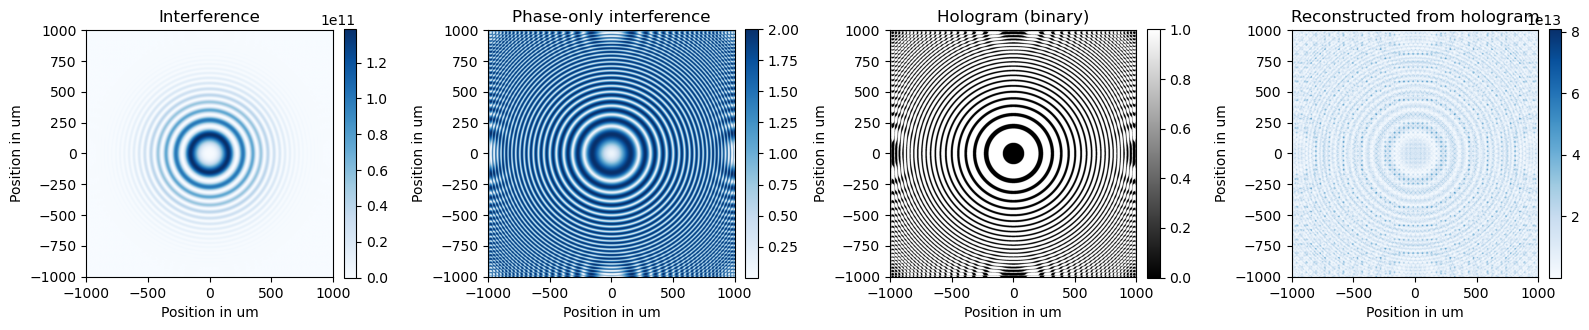

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs = axs.ravel()

# ensure extent and colormap are defined
extent_um = [x_m[0]*1e6, x_m[-1]*1e6, y_m[0]*1e6, y_m[-1]*1e6]
cmap = 'Blues'  # Changed to 'Blues' to match original colored figures

data_list = [
    (I_sum, "Interference", cmap),
    (I_sum2, "Phase-only interference", cmap),
    (hologram.astype(float), "Hologram (binary)", "gray"),
    (np.abs(E_image_holo)**2, "Reconstructed from hologram", cmap),  # Fixed: E_image_holo instead of E_holo
]

for ax, (data, title, cm) in zip(axs, data_list):
    im = ax.imshow(data, extent=extent_um, origin='lower', cmap=cm)
    ax.set_title(title)
    ax.set_xlabel("Position in um")
    ax.set_ylabel("Position in um")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()